# 第一章实验：上下文长度、平滑与泛化

这个实验依次完成：**划分文档 → 统计计数 → 比较参数 → 验证集选择 → 测试集评估**。

观察三个问题：上下文越长是否越好？平滑如何改变泛化？计数表规模怎样增长？

[第一章正文](../../docs/01-language-modeling.md) · [实验说明](README.md) · [静态结果](../../docs/experiments/01-ngram/README.md)

使用菜单 **Run → Run All Cells** 可从头执行。运行所需环境见实验说明。

## 1. 导入与实验参数

核心计数逻辑在 `ngram.py`，数据处理在 `corpus.py`。本 Notebook 显式组织训练和评估流程。

In [1]:
from pathlib import Path
import os
import sys

# 从仓库根目录或实验目录启动 Notebook 都可以。
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "docs/00-learning-path.md").exists())
CACHE = ROOT / "experiments/.cache"
CACHE.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE))

import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False})

sys.path.insert(0, str(ROOT / "experiments/01-ngram"))
from corpus import load_corpus
from ngram import BOS, EOS, UNK, NGram, encode, vocabulary, select_best

CONTEXTS = [0, 1, 2, 4, 8]
ALPHAS = [0.1, 1.0, 10.0, 100.0]
METHODS = ["uniform", "backoff"]
SEED = 42

def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 2. 按文档划分，建立训练词表

使用固定版本 D2L 讲义。每篇最多 1,200 个英文词；词表只从训练集建立，出现不足两次的词映射为 UNK。各文档历史独立重置，所有词与一个 EOS 参与评分。

In [2]:
raw, manifest = load_corpus(ROOT / "refs/d2l-en", seed=SEED)
vocab = vocabulary(raw["train"], min_count=2)
encoded = {name: encode(documents, vocab) for name, documents in raw.items()}

paths = [doc["path"] for docs in manifest["documents"].values() for doc in docs]
assert len(paths) == len(set(paths))

table(["集合", "文档", "计分 token（含 EOS）", "UNK 比例"], [
    [name, len(docs), sum(len(doc) + 1 for doc in docs),
     f"{sum(doc.count(UNK) for doc in docs) / sum(len(doc) + 1 for doc in docs):.2%}"]
    for name, docs in encoded.items()
])
print("词表大小：", len(vocab))
print("训练文档示例：", manifest["documents"]["train"][0]["path"])
print("前 15 个 token：", encoded["train"][0][:15])

| 集合 | 文档 | 计分 token（含 EOS） | UNK 比例 |
| --- | --- | --- | --- |
| train | 36 | 37496 | 3.80% |
| validation | 8 | 9081 | 11.07% |
| test | 8 | 8187 | 9.98% |
| topic_shift | 6 | 6917 | 15.74% |

词表大小： 2077
训练文档示例： chapter_preliminaries/ndarray.md
前 15 个 token： ['data', 'manipulation', 'in', 'order', 'to', 'get', 'anything', 'done', 'we', 'need', 'some', 'way', 'to', 'store', 'and']


## 3. 训练就是累积计数

$$C(h,w)=\text{训练集中上下文 }h\text{ 后接 }w\text{ 的次数}.$$

一次统计保存所有阶数，后续只改变概率计算方式，不重新读取验证数据来更新计数。

In [13]:
model = NGram(vocab, max_context=max(CONTEXTS)).fit(encoded["train"])
context = ("of",)
table(["上下文", "下一 token", "次数", "未平滑频率"], [
    [" ".join(context), word, count, f"{count / model.totals[1][context]:.4f}"]
    for word, count in model.counts[1][context].most_common(10)
])
print("零阶计数总量：", model.totals[0][()])

| 上下文 | 下一 token | 次数 | 未平滑频率 |
| --- | --- | --- | --- |
| of | the | 366 | 0.2964 |
| of | a | 56 | 0.0453 |
| of | <unk> | 48 | 0.0389 |
| of | our | 19 | 0.0154 |
| of | and | 18 | 0.0146 |
| of | each | 16 | 0.0130 |
| of | hidden | 16 | 0.0130 |
| of | an | 15 | 0.0121 |
| of | this | 14 | 0.0113 |
| of | with | 14 | 0.0113 |

零阶计数总量： 37496


## 4. 两种平滑使用同一个公式

$$P(w\mid h)=\frac{C(h,w)+\alpha P_{\mathrm{prior}}(w)}{C(h)+\alpha}.$$

- `uniform`：先验为 $1/V$。
- `backoff`：先验来自短一阶上下文，递归到零阶。

$\alpha$ 是虚拟计数**总量**。先手动比较一个上下文的两种预测。

In [4]:
history = [BOS] * max(CONTEXTS)
history[-2:] = ["of", "the"]
k, alpha = 2, 10.0
for method in METHODS:
    probabilities = {word: model.probability(word, history, k, alpha, method) for word in vocab}
    assert abs(sum(probabilities.values()) - 1) < 1e-10
    top = sorted(probabilities.items(), key=lambda item: item[1], reverse=True)[:8]
    print(method, [(word, round(p, 4)) for word, p in top])

uniform [('output', 0.0559), ('input', 0.0479), ('hidden', 0.0452), ('<unk>', 0.0346), ('decoder', 0.0346), ('previous', 0.0319), ('same', 0.0239), ('current', 0.0213)]
backoff [('output', 0.0567), ('input', 0.0487), ('hidden', 0.046), ('<unk>', 0.0358), ('decoder', 0.035), ('previous', 0.0322), ('same', 0.0248), ('encoder', 0.0216)]


## 5. 比较训练与验证损失

运行全部配置，只计算训练集和验证集。评分位置保持相同，平均 NLL 越低越好。

In [5]:
rows = []
for method in METHODS:
    for k in CONTEXTS:
        for alpha in ALPHAS:
            rows.append({"method": method, "k": k, "alpha": alpha,
                         "train": model.evaluate(encoded["train"], k, alpha, method),
                         "validation": model.evaluate(encoded["validation"], k, alpha, method)})
print("已评估配置数：", len(rows))
assert len({row["validation"]["targets"] for row in rows}) == 1
table(["方法", "k", "α", "训练 NLL", "验证 NLL"], [
    [row["method"], row["k"], row["alpha"], f'{row["train"]["nll"]:.4f}',
     f'{row["validation"]["nll"]:.4f}']
    for row in rows if row["alpha"] == (1.0 if 1.0 in ALPHAS else ALPHAS[0])
])

已评估配置数： 40


| 方法 | k | α | 训练 NLL | 验证 NLL |
| --- | --- | --- | --- | --- |
| uniform | 0 | 1.0 | 5.9480 | 5.7351 |
| uniform | 1 | 1.0 | 3.2285 | 6.2074 |
| uniform | 2 | 1.0 | 1.4276 | 7.2098 |
| uniform | 4 | 1.0 | 0.7141 | 7.5820 |
| uniform | 8 | 1.0 | 0.6900 | 7.6317 |
| backoff | 0 | 1.0 | 5.9480 | 5.7351 |
| backoff | 1 | 1.0 | 3.2250 | 5.9157 |
| backoff | 2 | 1.0 | 1.3462 | 6.5621 |
| backoff | 4 | 1.0 | 0.2419 | 6.7752 |
| backoff | 8 | 1.0 | 0.0191 | 6.7968 |

## 6. 固定平滑强度，观察上下文长度

修改 `alpha_to_plot` 后重新运行本单元，比较平滑强弱。

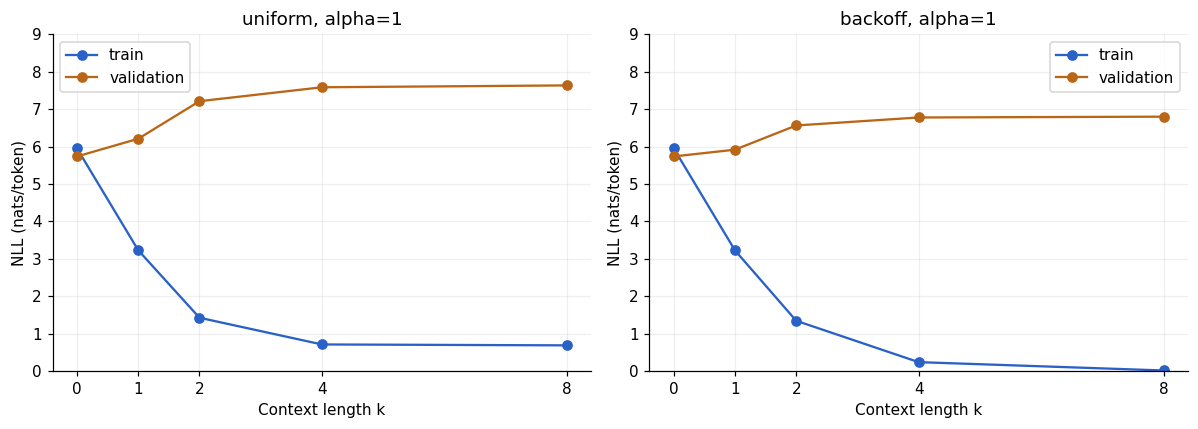

In [6]:
alpha_to_plot = 1.0 if 1.0 in ALPHAS else ALPHAS[0]

def draw_loss_curves(alpha):
    fig, axes = plt.subplots(1, len(METHODS), figsize=(11, 4), squeeze=False)
    for ax, method in zip(axes[0], METHODS):
        selected_rows = [row for row in rows if row["method"] == method and row["alpha"] == alpha]
        for split, color in [("train", "#2961c7"), ("validation", "#b96616")]:
            ax.plot([row["k"] for row in selected_rows], [row[split]["nll"] for row in selected_rows],
                    "o-", color=color, label=split)
        ax.set(title=f"{method}, alpha={alpha:g}", xlabel="Context length k",
               ylabel="NLL (nats/token)", xticks=CONTEXTS, ylim=(0, 9))
        ax.legend()
        ax.grid(alpha=0.2)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

draw_loss_curves(alpha_to_plot)

## 7. 验证损失热力图

每个格子是一组已训练计数与平滑配置的验证成绩。

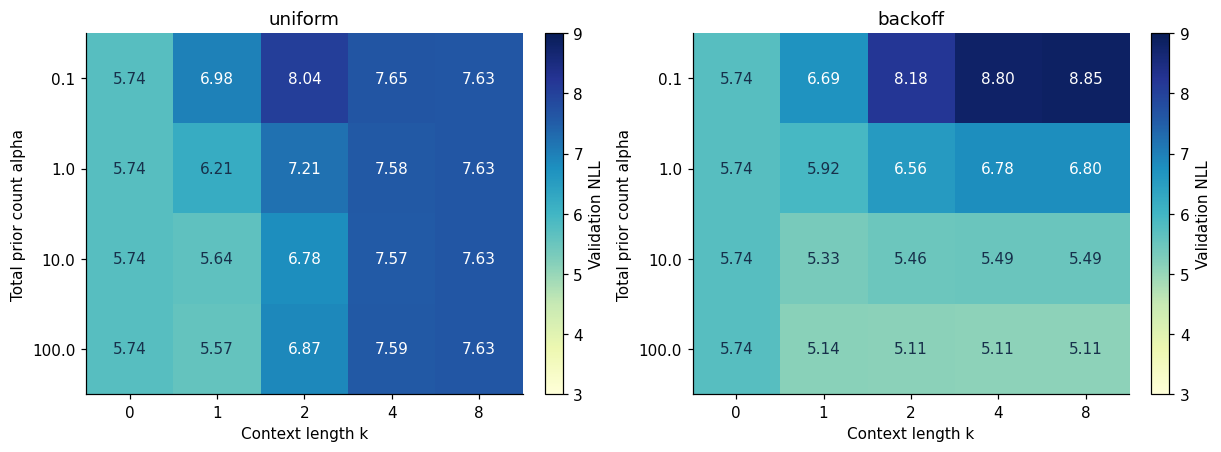

In [7]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(11, 4), squeeze=False, constrained_layout=True)
for ax, method in zip(axes[0], METHODS):
    values = np.array([[next(row["validation"]["nll"] for row in rows
                             if row["method"] == method and row["k"] == k and row["alpha"] == alpha)
                        for k in CONTEXTS] for alpha in ALPHAS])
    chart = ax.imshow(values, cmap="YlGnBu", vmin=3, vmax=9, aspect="auto")
    ax.set(title=method, xlabel="Context length k", ylabel="Total prior count alpha",
           xticks=range(len(CONTEXTS)), xticklabels=CONTEXTS,
           yticks=range(len(ALPHAS)), yticklabels=ALPHAS)
    for i in range(len(ALPHAS)):
        for j in range(len(CONTEXTS)):
            ax.text(j, i, f"{values[i,j]:.2f}", ha="center", va="center",
                    color="white" if values[i,j] > 6.5 else "#17304b")
    fig.colorbar(chart, ax=ax, label="Validation NLL")
display(fig)
plt.close(fig)

## 8. 样本稀疏性与计数表规模

左图统计不同训练上下文各有多少次观测；右图统计验证位置的上下文在训练中是否出现。

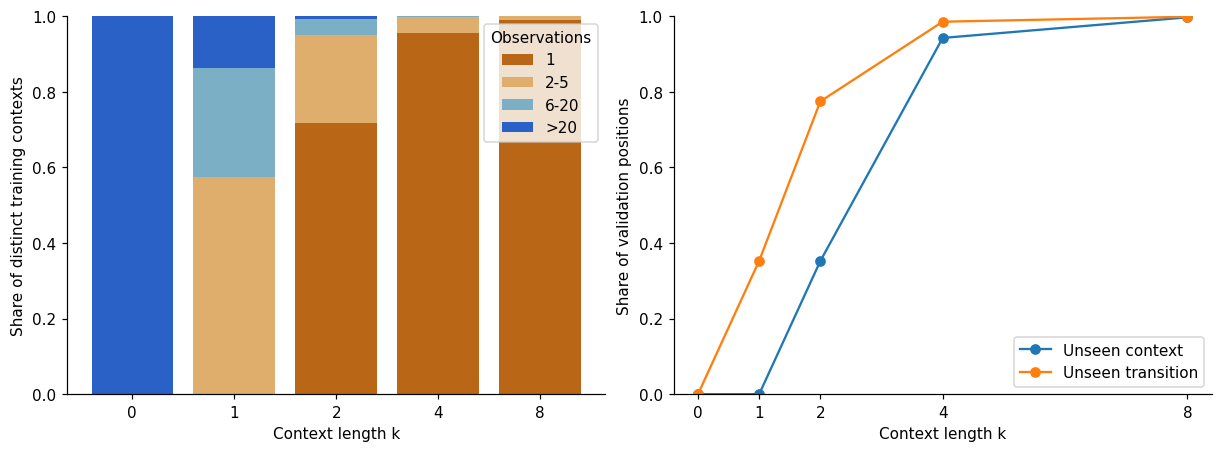

| k | 本阶上下文数 | 累计转移项 |
| --- | --- | --- |
| 0 | 1 | 2077 |
| 1 | 2077 | 20246 |
| 2 | 18140 | 51112 |
| 4 | 35100 | 122571 |
| 8 | 36953 | 270215 |

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
bottom = np.zeros(len(CONTEXTS))
for label, low, high, color in [("1",1,1,"#b96616"), ("2-5",2,5,"#dfad6c"),
                                ("6-20",6,20,"#7bafc5"), (">20",21,np.inf,"#2961c7")]:
    shares = np.array([sum(low <= n <= high for n in model.totals[k].values())
                       / len(model.totals[k]) for k in CONTEXTS])
    axes[0].bar(range(len(CONTEXTS)), shares, bottom=bottom, label=label, color=color)
    bottom += shares
axes[0].set(xlabel="Context length k", ylabel="Share of distinct training contexts",
            xticks=range(len(CONTEXTS)), xticklabels=CONTEXTS, ylim=(0,1))
axes[0].legend(title="Observations")
by_k = {row["k"]: row["validation"] for row in rows}
for key, label in [("unseen_context_rate", "Unseen context"),
                    ("unseen_transition_rate", "Unseen transition")]:
    axes[1].plot(CONTEXTS, [by_k[k][key] for k in CONTEXTS], "o-", label=label)
axes[1].set(xlabel="Context length k", ylabel="Share of validation positions",
            xticks=CONTEXTS, ylim=(0,1))
axes[1].legend()
display(fig)
plt.close(fig)

table(["k", "本阶上下文数", "累计转移项"], [
    [k, len(model.counts[k]), sum(len(c) for order in range(k+1) for c in model.counts[order].values())]
    for k in CONTEXTS
])

## 9. 转移概率热力图

展示 12 个常见词之间的转移，概率分母包含完整词表。

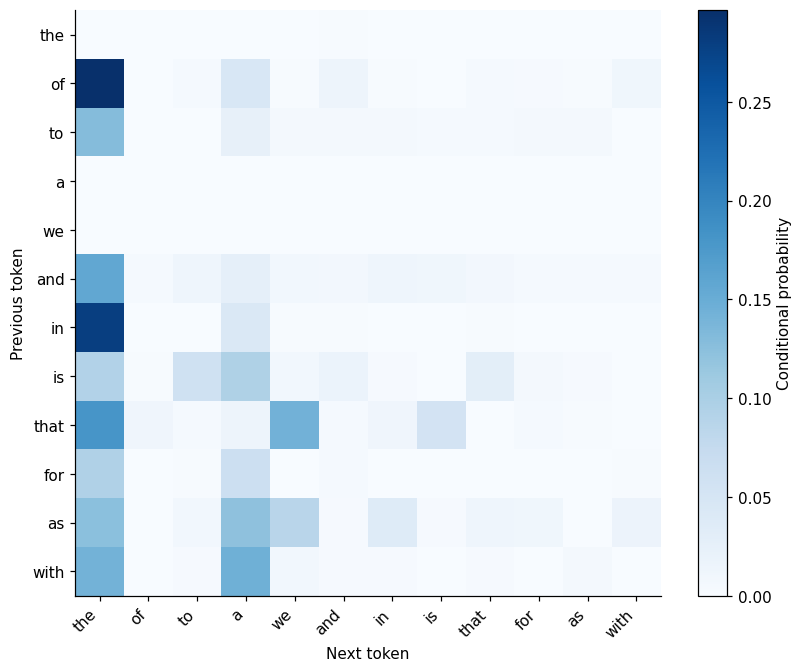

In [9]:
words = [word for word, _ in model.counts[0][()].most_common() if word not in {BOS, EOS, UNK}][:12]
matrix = np.array([[model.counts[1].get((context,), {}).get(word, 0) / model.totals[1][(context,)]
                    for word in words] for context in words])
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
im = ax.imshow(matrix, cmap="Blues")
ax.set(xticks=range(len(words)), xticklabels=words, yticks=range(len(words)), yticklabels=words,
       xlabel="Next token", ylabel="Previous token")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.colorbar(im, ax=ax, label="Conditional probability")
display(fig)
plt.close(fig)

## 10. 先选择，再评估测试集

冻结验证集选中的配置，随后计算测试集及计算性能主题文档的损失。

In [10]:
best = select_best(rows)
configuration = {key: best[key] for key in ("k", "alpha", "method")}
heldout = {name: model.evaluate(encoded[name], **configuration) for name in ("test", "topic_shift")}
print("验证集选中：", configuration)
table(["集合", "NLL", "UNK 比例"], [
    ["validation", f'{best["validation"]["nll"]:.6f}', f'{best["validation"]["unk_rate"]:.2%}'],
    *[[name, f'{score["nll"]:.6f}', f'{score["unk_rate"]:.2%}'] for name, score in heldout.items()]
])
# 保留完整数值，方便与脚本结果核对。
summary = {"configuration": configuration, "validation_nll": best["validation"]["nll"],
           "test_nll": heldout["test"]["nll"], "topic_shift_nll": heldout["topic_shift"]["nll"]}
print(json.dumps(summary, ensure_ascii=False, indent=2))

验证集选中： {'k': 4, 'alpha': 100.0, 'method': 'backoff'}


| 集合 | NLL | UNK 比例 |
| --- | --- | --- |
| validation | 5.105842 | 11.07% |
| test | 5.035537 | 9.98% |
| topic_shift | 5.158242 | 15.74% |

{
  "configuration": {
    "k": 4,
    "alpha": 100.0,
    "method": "backoff"
  },
  "validation_nll": 5.105841587443518,
  "test_nll": 5.035536525483765,
  "topic_shift_nll": 5.158242410557514
}


## 11. 交互比较

下拉框只切换已计算的训练与验证结果，不重新训练，也不使用测试成绩选择参数。

In [12]:
import ipywidgets as widgets
alpha_control = widgets.SelectionSlider(options=ALPHAS, value=alpha_to_plot, description="alpha", continuous_update=False)
curve_output = widgets.interactive_output(draw_loss_curves, {"alpha": alpha_control})
display(widgets.VBox([alpha_control, curve_output]))

## 实验结论

默认配置下，较长上下文使训练拟合更好，但弱平滑下验证损失上升；递归借用短上下文统计可以改善泛化。增加上下文也会扩大计数表，应同时比较预测质量和存储规模。

练习：在训练数据、词表和划分不变的前提下，修改 `ALPHAS`，重新观察训练与验证曲线。探索阶段只使用验证集，测试集用于最终确定方案后的评估。

语料来源：Aston Zhang、Zachary C. Lipton、Mu Li、Alexander J. Smola 及贡献者，[Dive into Deep Learning](https://github.com/d2l-ai/d2l-en)，版本 `23d7a5aecceee57d1292c56e90cce307f183bb0a`，原文许可 [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)。